# Example use of non-cartesian MORSE

## Load saved data
Plot data to ensure correct sorting

(7200, 3)
(32, 7200)


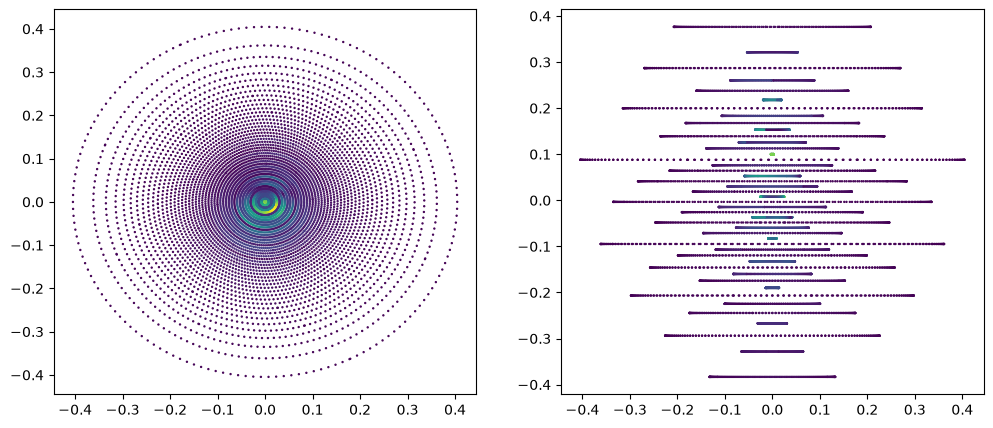

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

data_path = Path("test_data")

trajectory = np.load(data_path / "traj.npy")
data = np.load(data_path / "data.npy")
noise_cov = np.load(data_path / "noise_cov.npy")

print(trajectory.shape)
print(data.shape)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(trajectory[:, 0], trajectory[:, 1], s=0.5, c=np.abs(data[0, :]))
axes[1].scatter(trajectory[:, 0], trajectory[:, 2], s=0.5, c=np.abs(data[0, :]))
plt.show()

In [4]:
from morse_pi import morse_pi

sens = morse_pi(
    data=data,
    trajectory=trajectory,
    resolution=(64, 64, 8),
    backend="torchkbnufft-cpu",
    noise_cov=noise_cov,
    noise_whiten=True,
    noise_colour_power=2,
)

100%|██████████| 10/10 [00:06<00:00,  1.48it/s]


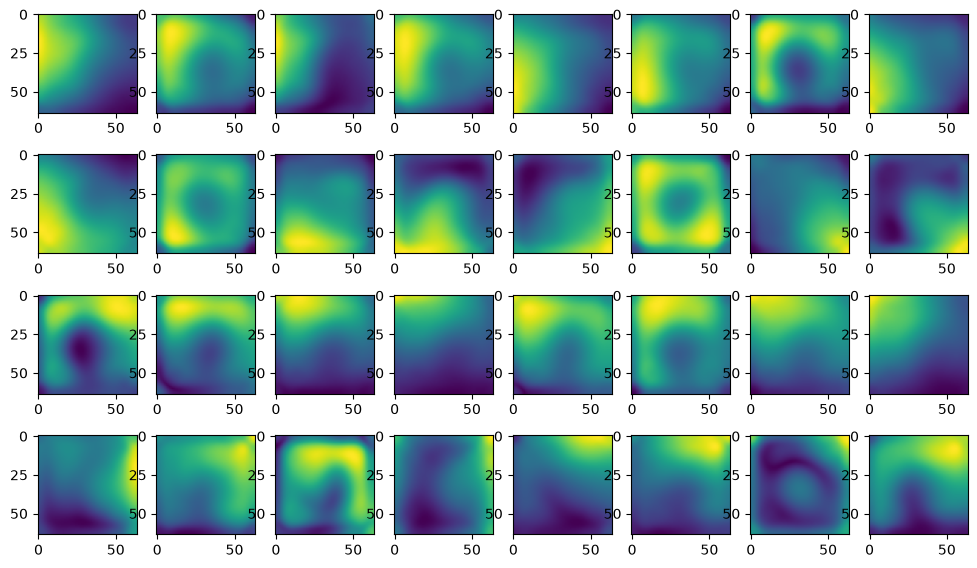

In [7]:
ref_dx = 0
_, axes = plt.subplots(4, 8, figsize=(12, 7))
for idx, ax in enumerate(axes.ravel()):
    ax.imshow(np.abs(sens[..., 4, idx, ref_dx]))
    # ax.imshow(np.angle(sens[..., 4, idx, ref_dx]), vmin=-np.pi, vmax=np.pi)

plt.show()